# FA&EFER – Fairness study (corrected): multi-seed, controlled ablation, statistical tests

**What was wrong with the first comparison** and what this notebook does about it:

| Problem in the first version | Fix here |
|---|---|
| One run per setting – Fear has only 74 test images, so one run is mostly noise | **5 seeds per condition**, reported as mean ± std |
| "With" and "without" were different seeds / different pipelines (confounded) | **Same seeds, same split, same recipe**; only the fairness component changes |
| Fairness was a bundle (weights + F1 selection + ensemble + calibration) | **Ablation**: each component added one at a time |
| Per-class calibration offsets tuned on a small val set (7 free parameters) → overfit, hurt Fear | Replaced with **logit adjustment** (1 parameter τ, chosen on validation only) |
| No significance tests | **Paired t-test over seeds** + **bootstrap CI over test images** |

**Conditions**

| ID | Class weights | Best-epoch rule | Post-hoc |
|---|---|---|---|
| A  | none (p=0) | val accuracy | – |
| A+LA | none | val accuracy | logit adjustment |
| B  | p = 0.5 | val accuracy | – |
| C  | p = 0.5 | val macro-F1 | – |
| C+LA | p = 0.5 | val macro-F1 | logit adjustment |
| E  | p = 1.0 (full inverse freq.) | val macro-F1 | – |

Training time: ≈ 12 min per run on an L4 → 4 trained conditions × 5 seeds = 20 runs ≈ 4 h. Everything is **resumable** (finished runs are skipped), so you can stop and restart. Set `SEEDS` to 3 values in section 3 for a quicker (weaker) study.

## 1. Setup (Colab or local)

In [1]:
import os, sys, json, glob, random, subprocess
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR   = "/content/drive/MyDrive/Sem3-CaseStudy"  # folder on Google Drive
    DATASET_ZIP = f"{DRIVE_DIR}/Dataset.zip"              # zip of Dataset (train/1..7, test/1..7)
    WEIGHTS     = f"{DRIVE_DIR}/resnet50_ft_weight.pkl"   # VGGFace2 ResNet-50 weights
    MODELS_DIR  = f"{DRIVE_DIR}/models"                   # checkpoints + results (survive disconnects)
    DATA_DIR    = "/content/Dataset"                      # local copy for fast loading
    SCRIPT_DIR  = "/content/fer_scripts"
    WORKERS     = 2
else:  # local Jupyter / VS Code on the laptop - run from project directory
    here = os.path.abspath(os.getcwd())
    PROJECT_DIR = next((d for d in [here, os.path.dirname(here)]
                        if os.path.isdir(os.path.join(d, "TestDb", "DATASET"))), None)
    assert PROJECT_DIR, "Open this notebook from the project root or notebooks folder"
    DATA_DIR   = os.path.join(PROJECT_DIR, "TestDb", "DATASET")
    WEIGHTS    = os.path.join(PROJECT_DIR, "models", "resnet50_ft_weight.pkl")
    MODELS_DIR = os.path.join(PROJECT_DIR, "models")
    SCRIPT_DIR = os.path.join(PROJECT_DIR, "notebooks", "_nb_scripts")
    WORKERS    = 4

os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(SCRIPT_DIR, exist_ok=True)
sys.path.insert(0, SCRIPT_DIR)
EVAL_WORKERS = 0 if os.name == "nt" else WORKERS   # in-notebook DataLoader workers are unreliable on Windows
print("Colab" if IN_COLAB else "Local", "| data:", DATA_DIR, "| models:", MODELS_DIR)

Mounted at /content/drive
Colab | data: /content/Dataset | models: /content/drive/MyDrive/Sem3-CaseStudy/models


In [2]:
# Colab already has everything these notebooks need (torch, torchvision, scikit-learn, matplotlib).
# Locally, use the project venv (requirements.txt).
import sklearn, matplotlib
print("scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

scikit-learn 1.6.1 | matplotlib 3.10.0


## 2. Data and VGGFace2 weights

In [3]:
import zipfile, shutil, os

if IN_COLAB and not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
    # 1. Copy the zip file from Drive to local Colab storage
    !cp "/content/drive/MyDrive/Sem3-CaseStudy/Dataset.zip" "/content/Dataset.zip"

    # 2. Extract it locally
    with zipfile.ZipFile("/content/Dataset.zip", 'r') as zip_ref:
        zip_ref.extractall("/content/Dataset")

    print("Dataset successfully extracted to local Colab storage!")

    # Auto-detect train/ and test/ inside /content/Dataset
    if not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
        for root, dirs, _ in os.walk("/content/Dataset"):
            if "train" in dirs and "test" in dirs:
                DATA_DIR = root
                break

assert os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test"), f"train/ and test/ not found in {DATA_DIR}"

import matplotlib.pyplot as plt
NAMES = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
counts = {s: [len(glob.glob(f"{DATA_DIR}/{s}/{k}/*")) for k in range(1, 8)] for s in ["train", "test"]}
for s in counts:
    print(s, dict(zip(NAMES, counts[s])), "total", sum(counts[s]))

Dataset successfully extracted to local Colab storage!
train {'Surprise': 1290, 'Fear': 281, 'Disgust': 717, 'Happiness': 4772, 'Sadness': 1982, 'Anger': 705, 'Neutral': 2524} total 12271
test {'Surprise': 329, 'Fear': 74, 'Disgust': 160, 'Happiness': 1185, 'Sadness': 478, 'Anger': 162, 'Neutral': 680} total 3068


In [4]:
if not os.path.exists(WEIGHTS) and IN_COLAB:
    # resnet50_ft link from the README of github.com/cydonia999/VGGFace2-pytorch
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gdown"], check=True)
    subprocess.run(["gdown", "--fuzzy", "https://drive.google.com/open?id=1A94PAAnwk6L7hXdBXLFosB_s0SzEhAFU", "-O", WEIGHTS])
if os.path.exists(WEIGHTS) and os.path.getsize(WEIGHTS) > 150e6:
    print("VGGFace2 weights OK:", round(os.path.getsize(WEIGHTS) / 1e6), "MB")
else:
    print("VGGFace2 weights NOT found at", WEIGHTS, "- needed only to TRAIN. Already-trained models can still be evaluated.")

VGGFace2 weights OK: 165 MB


### Training script (same as before: ResNet-50 + VGGFace2, RAF-DB)

In [5]:
# train_emotion_resnet50_vggface2.py - identical to the file in D:/Research4
open(os.path.join(SCRIPT_DIR, 'train_emotion_resnet50_vggface2.py'), "w", encoding="utf-8").write(r'''"""
Emotion classifier: ResNet-50 initialised with VGGFace2 weights, fine-tuned on RAF-DB.

Why this script exists
----------------------
The usual reasons a "ResNet-50 + VGGFace2" FER model gets stuck at 30-40% are:
  1. The backbone is never actually given VGGFace2 weights (weights=None, or
     load_state_dict(strict=False) silently skipping every key).
  2. The VGGFace2 ResNet-50 weights (converted from Caffe) are loaded into
     torchvision's resnet50. Keys match, but the Caffe model puts the stride-2
     on the first 1x1 conv of each bottleneck and uses a ceil_mode max-pool, so
     the features come out wrong.
  3. Wrong input format. The VGGFace2 Caffe weights expect BGR pixels in the
     0-255 range minus a per-channel mean, NOT ImageNet mean/std on 0-1 RGB.
This script fixes all three and refuses to train if the weights did not load.

Weights
-------
Use resnet50_ft_weight.pkl (ResNet-50 pre-trained on MS1M, fine-tuned on
VGGFace2) from https://github.com/cydonia999/VGGFace2-pytorch (README, "Pretrained
models"). The network definition below follows that repository (MIT licence).

Usage
-----
python train_emotion_resnet50_vggface2.py \
    --data_dir "D:/Research4/TestDb/DATASET" \
    --weights  "D:/Research4/models/resnet50_ft_weight.pkl" \
    --out      "D:/Research4/models/best_resnet50_vggface2_emotion.pth"

The data folder must contain train/1..7 and test/1..7 (RAF-DB convention:
1 Surprise, 2 Fear, 3 Disgust, 4 Happiness, 5 Sadness, 6 Anger, 7 Neutral).
"""
import argparse
import math
import os
import pickle
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

EMOTIONS = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
MEAN_BGR = torch.tensor([91.4953, 103.8827, 131.0912]).view(3, 1, 1)  # resnet50_ft.prototxt


# --------------------------------------------------------------------------
# VGGFace2 ResNet-50 (Caffe layout: stride on conv1 of the bottleneck, ceil_mode max-pool)
# --------------------------------------------------------------------------
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 1, stride=stride, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, planes * 4, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * 4)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)


class VGGFace2ResNet50(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()
        self.inplanes = 64
        self.conv1 = nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=0, ceil_mode=True)
        self.layer1 = self._make_layer(64, 3)
        self.layer2 = self._make_layer(128, 4, stride=2)
        self.layer3 = self._make_layer(256, 6, stride=2)
        self.layer4 = self._make_layer(512, 3, stride=2)   # Grad-CAM target layer
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2048, num_classes)          # new emotion head ("fc" is the 8631-way identity head, not used)

    def _make_layer(self, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * 4:
            downsample = nn.Sequential(nn.Conv2d(self.inplanes, planes * 4, 1, stride=stride, bias=False),
                                       nn.BatchNorm2d(planes * 4))
        layers = [Bottleneck(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * 4
        layers += [Bottleneck(self.inplanes, planes) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def features(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return torch.flatten(self.avgpool(x), 1)

    def forward(self, x):
        return self.head(self.dropout(self.features(x)))


def load_vggface2_weights(model, path):
    """Load VGGFace2 weights and FAIL LOUDLY if they do not cover the backbone."""
    if path.endswith(".pkl"):
        with open(path, "rb") as f:
            src = pickle.load(f, encoding="latin1")
        src = {k: torch.from_numpy(v) for k, v in src.items()}
    else:
        src = torch.load(path, map_location="cpu")
        src = src.get("state_dict", src)
        src = {k.replace("module.", ""): v for k, v in src.items()}
    own = model.state_dict()
    # num_batches_tracked buffers are not stored in Caffe conversions; they do not matter.
    backbone_keys = [k for k in own if not k.startswith("head.") and not k.endswith("num_batches_tracked")]
    loaded, shape_bad = 0, []
    for k in backbone_keys:
        if k in src:
            if src[k].shape == own[k].shape:
                own[k].copy_(src[k]); loaded += 1
            else:
                shape_bad.append(k)
    model.load_state_dict(own)
    real_missing = [k for k in backbone_keys if k not in src]
    print(f"[weights] loaded {loaded}/{len(backbone_keys)} backbone tensors "
          f"(missing {len(real_missing)}, shape mismatch {len(shape_bad)})")
    if real_missing or shape_bad:
        print("  first missing:", real_missing[:5], " first shape mismatch:", shape_bad[:5])
        raise SystemExit("VGGFace2 weights did not load into the backbone - stopping. "
                         "Use resnet50_ft_weight.pkl from cydonia999/VGGFace2-pytorch.")


# --------------------------------------------------------------------------
# Data
# --------------------------------------------------------------------------
class ToVGGFace2Tensor:
    """PIL RGB -> float tensor in BGR 0-255 minus VGGFace2 mean (what the Caffe weights expect)."""
    def __call__(self, img):
        t = transforms.functional.pil_to_tensor(img).float()   # RGB, 0-255
        return t[[2, 1, 0]] - MEAN_BGR


def build_transforms(size):
    train_tf = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.RandomResizedCrop(size, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.RandomRotation(10)], p=0.5),
        transforms.ColorJitter(0.2, 0.2, 0.2),
        ToVGGFace2Tensor(),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), value=0),
    ])
    test_tf = transforms.Compose([transforms.Resize((size, size)), ToVGGFace2Tensor()])
    return train_tf, test_tf


def list_images(root):
    items = []
    for k in range(1, 8):
        d = os.path.join(root, str(k))
        for f in sorted(os.listdir(d)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                items.append((os.path.join(d, f), k - 1))   # folder 1..7 -> class 0..6
    return items


class ImageList(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y


# --------------------------------------------------------------------------
# Train / evaluate
# --------------------------------------------------------------------------
def evaluate(model, loader, device, tta=True):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            if tta:
                logits = logits + model(torch.flip(x, dims=[3]))   # horizontal-flip test-time augmentation
            ps += logits.argmax(1).cpu().tolist(); ys += y.tolist()
    ys, ps = np.array(ys), np.array(ps)
    return (ys == ps).mean(), f1_score(ys, ps, average="macro"), ys, ps


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--weights", required=True)
    ap.add_argument("--out", default="models/best_resnet50_vggface2_emotion.pth")
    ap.add_argument("--epochs", type=int, default=25)
    ap.add_argument("--warmup_epochs", type=int, default=2, help="head-only epochs before unfreezing")
    ap.add_argument("--batch_size", type=int, default=64)
    ap.add_argument("--lr", type=float, default=1e-4, help="backbone learning rate (head gets 10x)")
    ap.add_argument("--img_size", type=int, default=224)
    ap.add_argument("--val_frac", type=float, default=0.1)
    ap.add_argument("--label_smoothing", type=float, default=0.1)
    ap.add_argument("--class_weight_power", type=float, default=0.5, help="0 = no weighting, 1 = full inverse frequency")
    ap.add_argument("--patience", type=int, default=6)
    ap.add_argument("--select_metric", choices=["macro_f1", "accuracy"], default="macro_f1",
                    help="validation metric for choosing the best epoch; 'accuracy' + --class_weight_power 0 "
                         "= baseline WITHOUT fairness mitigation")
    ap.add_argument("--workers", type=int, default=4)
    ap.add_argument("--seed", type=int, default=42, help="training randomness (init of head, shuffling, augmentation)")
    ap.add_argument("--split_seed", type=int, default=42, help="keep at 42 so every model shares the same validation split")
    ap.add_argument("--resume", action="store_true", help="continue from <out>_last.pth after a crash")
    ap.add_argument("--eval_only", action="store_true", help="skip training; evaluate the best checkpoint on TEST")
    ap.add_argument("--no_amp", action="store_true", help="disable mixed precision")
    ap.add_argument("--no_cudnn", action="store_true", help="disable cuDNN (slower; last resort)")
    a = ap.parse_args()

    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed); torch.cuda.manual_seed_all(a.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("[device]", device, "| torch", torch.__version__, "| cuDNN", torch.backends.cudnn.version() if device.type == "cuda" else "-")
    if device.type == "cuda":
        print("[gpu]", torch.cuda.get_device_name(0))
        torch.backends.cudnn.benchmark = False
        if a.no_cudnn:
            torch.backends.cudnn.enabled = False
    use_amp = device.type == "cuda" and not a.no_amp

    # data: stratified validation split from TRAIN; TEST is used once at the end
    train_all = list_images(os.path.join(a.data_dir, "train"))
    test_items = list_images(os.path.join(a.data_dir, "test"))
    labels = np.array([y for _, y in train_all])
    tr_idx, va_idx = next(StratifiedShuffleSplit(1, test_size=a.val_frac, random_state=a.split_seed).split(labels, labels))
    train_tf, test_tf = build_transforms(a.img_size)
    tr = ImageList([train_all[i] for i in tr_idx], train_tf)
    va = ImageList([train_all[i] for i in va_idx], test_tf)
    te = ImageList(test_items, test_tf)
    counts = np.bincount(labels[tr_idx], minlength=7)
    print("[data] train", len(tr), "val", len(va), "test", len(te))
    print("[data] train counts:", dict(zip(EMOTIONS, counts.tolist())))
    pin = device.type == "cuda"
    tl = DataLoader(tr, a.batch_size, shuffle=True, num_workers=a.workers, pin_memory=pin, drop_last=True)
    vl = DataLoader(va, a.batch_size, shuffle=False, num_workers=a.workers, pin_memory=pin)
    tel = DataLoader(te, a.batch_size, shuffle=False, num_workers=a.workers, pin_memory=pin)

    # model
    model = VGGFace2ResNet50(num_classes=7)
    load_vggface2_weights(model, a.weights)
    model.to(device)

    w = (counts.sum() / (7.0 * counts)) ** a.class_weight_power
    w = torch.tensor(w / w.mean(), dtype=torch.float32, device=device)
    print("[loss] class weights:", [round(float(v), 3) for v in w])
    criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=a.label_smoothing)

    backbone = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    opt = torch.optim.AdamW([{"params": backbone, "lr": a.lr}, {"params": model.head.parameters(), "lr": a.lr * 10}],
                            weight_decay=1e-4)
    steps_per_epoch = len(tl); total = a.epochs * steps_per_epoch; warm = steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_f1, best_ep, bad, start_ep = -1, 0, 0, 1
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    last_path = os.path.splitext(a.out)[0] + "_last.pth"
    if a.resume and os.path.exists(last_path):
        st = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"])
        scaler.load_state_dict(st["scaler"])
        best_f1, best_ep, bad, start_ep = st["best_f1"], st["best_ep"], st["bad"], st["epoch"] + 1
        print(f"[resume] continuing from epoch {start_ep} (best val {a.select_metric} so far {best_f1*100:.2f}% at epoch {best_ep})")
    elif a.resume:
        print(f"[resume] {last_path} not found - starting from scratch")
    if a.eval_only:
        start_ep = a.epochs + 1
    oom_count = 0
    for ep in range(start_ep, a.epochs + 1):
        head_only = ep <= a.warmup_epochs
        for p in backbone:
            p.requires_grad = not head_only
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            try:
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    loss = criterion(model(x), y)
                scaler.scale(loss).backward()
            except RuntimeError as e:
                msg = str(e).lower()
                if "out of memory" in msg:
                    # Another program briefly took GPU memory: free the cache, skip this batch, carry on.
                    oom_count += 1
                    del e
                    opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                    print(f"[warn] CUDA out of memory - skipped batch ({oom_count} so far). Close other GPU programs (e.g. the running app).")
                    if oom_count > 25:
                        raise SystemExit("Too many out-of-memory errors - rerun with --resume --batch_size 48")
                    time.sleep(2)
                    continue
                # Rare cuDNN failures (e.g. CUDNN_STATUS_BAD_PARAM_STREAM_MISMATCH) should not kill a long run:
                # skip this batch and continue with cuDNN disabled.
                if "cudnn" not in msg or not torch.backends.cudnn.enabled:
                    raise
                print(f"[warn] cuDNN error, skipping batch and disabling cuDNN for the rest of the run: {e}")
                torch.backends.cudnn.enabled = False
                opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                continue
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(y)
        acc, mf1, _, _ = evaluate(model, vl, device)
        print(f"epoch {ep:02d} {'(head only) ' if head_only else ''}loss {run_loss/len(tr):.4f} | "
              f"val acc {acc*100:.2f}% | val macro-F1 {mf1*100:.2f}% | {time.time()-t0:.0f}s")
        sel = mf1 if a.select_metric == "macro_f1" else acc
        if sel > best_f1:
            best_f1, best_ep, bad = sel, ep, 0
            torch.save({"state_dict": model.state_dict(), "classes": EMOTIONS, "img_size": a.img_size,
                        "preprocess": "RGB->BGR, 0-255, minus mean_bgr [91.4953, 103.8827, 131.0912]",
                        "val_macro_f1": mf1, "epoch": ep, "seed": a.seed, "split_seed": a.split_seed,
                        "val_frac": a.val_frac, "class_weight_power": a.class_weight_power,
                        "select_metric": a.select_metric,
                        "fairness_mitigation": a.class_weight_power > 0 or a.select_metric == "macro_f1"}, a.out)
        elif not head_only:
            bad += 1
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": ep, "best_f1": best_f1, "best_ep": best_ep, "bad": bad}, last_path)
        if not head_only and bad >= a.patience:
            print("[early stop]"); break

    # final, one-time test evaluation with the best checkpoint
    best = torch.load(a.out, map_location=device)
    model.load_state_dict(best["state_dict"]); best_ep = best.get("epoch", best_ep)
    acc, mf1, ys, ps = evaluate(model, tel, device)
    print(f"\n[best epoch {best_ep}] TEST accuracy {acc*100:.2f}% | TEST macro-F1 {mf1*100:.2f}%")
    print(classification_report(ys, ps, target_names=EMOTIONS, digits=4, zero_division=0))
    print("confusion matrix (rows = true, cols = predicted):")
    print(confusion_matrix(ys, ps))


if __name__ == "__main__":
    main()
''')
print("written", 'train_emotion_resnet50_vggface2.py')

written train_emotion_resnet50_vggface2.py


## 3. Experiment configuration

In [7]:
import numpy as np, pandas as pd, torch, itertools, time

SEEDS = [42, 7, 2024, 123, 999]          # use 3 seeds for a quick run; 5+ recommended for a paper
# (name, class_weight_power, select_metric)
TRAINED = {
    "A": (0.0, "accuracy"),   # no fairness
    "B": (0.5, "accuracy"),   # + class weights
    "C": (0.5, "macro_f1"),   # + macro-F1 model selection
    "E": (1.0, "macro_f1"),   # stronger weighting
}
STUDY_DIR = os.path.join(MODELS_DIR, "fairness_study")
os.makedirs(STUDY_DIR, exist_ok=True)
MINORITY = [1, 2, 5]                      # Fear, Disgust, Anger (<7% of training images)
print("runs to train:", len(TRAINED) * len(SEEDS))

runs to train: 20


In [8]:
def run(args):
    """Run one of the project scripts with this notebook's Python and stream its output."""
    print(">", " ".join(args), flush=True)
    p = subprocess.Popen([sys.executable, "-u"] + args, cwd=SCRIPT_DIR, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError("Step failed - fix the error above and run this cell again (training resumes).")



def train_run(cond, seed):
    """Train one (condition, seed) model unless finished. Resumable."""
    p, sel = TRAINED[cond]
    out = os.path.join(STUDY_DIR, f"{cond}_s{seed}.pth")
    done = out.replace(".pth", ".done")
    if os.path.exists(done):
        print(f"[skip] {cond} seed {seed} already trained"); return out
    run(["train_emotion_resnet50_vggface2.py", "--data_dir", DATA_DIR, "--weights", WEIGHTS,
         "--split_seed", "42", "--seed", str(seed), "--out", out, "--workers", str(WORKERS), "--resume",
         "--class_weight_power", str(p), "--select_metric", sel, "--patience", "8"])
    open(done, "w").write("done")
    return out

## 4. Train all runs (long – resumable)
Re-run this cell after any disconnect; finished runs are skipped and an interrupted run continues from its last epoch.

In [9]:
for seed in SEEDS:
    for cond in TRAINED:
        train_run(cond, seed)
print("all runs finished")

[skip] A seed 42 already trained
[skip] B seed 42 already trained
[skip] C seed 42 already trained
[skip] E seed 42 already trained
[skip] A seed 7 already trained
[skip] B seed 7 already trained
[skip] C seed 7 already trained
[skip] E seed 7 already trained
[skip] A seed 2024 already trained
[skip] B seed 2024 already trained
[skip] C seed 2024 already trained
[skip] E seed 2024 already trained
[skip] A seed 123 already trained
[skip] B seed 123 already trained
[skip] C seed 123 already trained
[skip] E seed 123 already trained
[skip] A seed 999 already trained
[skip] B seed 999 already trained
[skip] C seed 999 already trained
> train_emotion_resnet50_vggface2.py --data_dir /content/Dataset/Dataset/Images --weights /content/drive/MyDrive/Sem3-CaseStudy/resnet50_ft_weight.pkl --split_seed 42 --seed 999 --out /content/drive/MyDrive/Sem3-CaseStudy/models/fairness_study/E_s999.pth --workers 2 --resume --class_weight_power 1.0 --select_metric macro_f1 --patience 8
[device] cuda | torch 2

## 5. Extract logits (validation + test) from every best checkpoint
Saved once to disk so that all later analysis (post-hoc methods, statistics, plots) is fast and needs no GPU.

In [10]:
import importlib, train_emotion_resnet50_vggface2 as T
importlib.reload(T)
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_all = T.list_images(os.path.join(DATA_DIR, "train"))
test_items = T.list_images(os.path.join(DATA_DIR, "test"))
lab = np.array([y for _, y in train_all])
tr_idx, va_idx = next(StratifiedShuffleSplit(1, test_size=0.1, random_state=42).split(lab, lab))   # same split as training
_, test_tf = T.build_transforms(224)
val_loader  = DataLoader(T.ImageList([train_all[i] for i in va_idx], test_tf), 64, shuffle=False, num_workers=EVAL_WORKERS)
test_loader = DataLoader(T.ImageList(test_items, test_tf), 64, shuffle=False, num_workers=EVAL_WORKERS)
TRAIN_COUNTS = np.bincount(lab[tr_idx], minlength=7)
PRIOR = TRAIN_COUNTS / TRAIN_COUNTS.sum()

@torch.no_grad()
def get_logits(model, loader):
    model.eval(); L, Y = [], []
    for x, y in loader:
        x = x.to(device)
        L.append(((model(x) + model(torch.flip(x, dims=[3]))) / 2).float().cpu().numpy()); Y.append(y.numpy())   # flip-TTA, averaged
    return np.concatenate(L), np.concatenate(Y)

def logits_for(cond, seed):
    f = os.path.join(STUDY_DIR, f"{cond}_s{seed}_logits.npz")
    if os.path.exists(f):
        d = np.load(f); return d["val"], d["yval"], d["test"], d["ytest"]
    model = T.VGGFace2ResNet50(7).to(device)
    ck = torch.load(os.path.join(STUDY_DIR, f"{cond}_s{seed}.pth"), map_location=device)
    model.load_state_dict(ck["state_dict"])
    lv, yv = get_logits(model, val_loader); lt, yt = get_logits(model, test_loader)
    np.savez(f, val=lv, yval=yv, test=lt, ytest=yt)
    return lv, yv, lt, yt

LOGITS = {}
for cond in TRAINED:
    for seed in SEEDS:
        LOGITS[(cond, seed)] = logits_for(cond, seed)
print("logits ready for", len(LOGITS), "runs")

logits ready for 20 runs


## 6. Post-hoc logit adjustment (replaces the per-class calibration)

`adjusted_logit_k = logit_k − τ · log(prior_k)` boosts rare classes in a principled way. Only **one** number (τ) is chosen, on the **validation** set (by balanced accuracy), never on test – so it cannot overfit the way 7 free per-class offsets did.

In [11]:
from sklearn.metrics import f1_score, balanced_accuracy_score
TAUS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]
def adjust(logits, tau): return logits - tau * np.log(PRIOR)

def pick_tau(lv, yv):
    scores = [balanced_accuracy_score(yv, adjust(lv, t).argmax(1)) for t in TAUS]
    return TAUS[int(np.argmax(scores))]

# system name -> (base condition, use logit adjustment?)
SYSTEMS = {"A": ("A", False), "A+LA": ("A", True), "B": ("B", False),
           "C": ("C", False), "C+LA": ("C", True), "E": ("E", False)}
PREDS, TAU_USED = {}, {}
for sysname, (base, use_la) in SYSTEMS.items():
    for seed in SEEDS:
        lv, yv, lt, yt = LOGITS[(base, seed)]
        tau = pick_tau(lv, yv) if use_la else 0.0
        TAU_USED[(sysname, seed)] = tau
        PREDS[(sysname, seed)] = adjust(lt, tau).argmax(1)
YTEST = LOGITS[("A", SEEDS[0])][3]
print("chosen tau per seed for A+LA:", [TAU_USED[("A+LA", s)] for s in SEEDS], "| C+LA:", [TAU_USED[("C+LA", s)] for s in SEEDS])

chosen tau per seed for A+LA: [0.75, 0.75, 0.75, 1.0, 0.75] | C+LA: [0.25, 0.5, 0.75, 0.25, 0.75]


## 7. Metrics per run

In [12]:
def fairness_metrics(y, p):
    rec = np.array([(p[y == k] == k).mean() for k in range(7)])
    return {"acc": (y == p).mean(), "bal_acc": rec.mean(), "macro_f1": f1_score(y, p, average="macro"),
            "worst_recall": rec.min(), "best_recall": rec.max(), "recall_gap": rec.max() - rec.min(),
            "recall_ratio": rec.min() / rec.max(), "minority_recall": rec[MINORITY].mean(),
            "majority_recall": np.delete(rec, MINORITY).mean(), **{f"rec_{NAMES[k]}": rec[k] for k in range(7)}}

rows = [{"system": s, "seed": sd, **fairness_metrics(YTEST, PREDS[(s, sd)])} for s in SYSTEMS for sd in SEEDS]
runs = pd.DataFrame(rows)
runs.to_csv(os.path.join(STUDY_DIR, "per_run_results.csv"), index=False)
KEY = ["acc", "bal_acc", "macro_f1", "worst_recall", "recall_gap", "recall_ratio", "minority_recall"]
agg = runs.groupby("system", sort=False)[KEY].agg(["mean", "std"])
pd.set_option("display.width", 220)
table = pd.DataFrame({m: [f"{100*agg[(m,'mean')][s]:.2f} ± {100*agg[(m,'std')][s]:.2f}" if m != "recall_ratio"
                          else f"{agg[(m,'mean')][s]:.3f} ± {agg[(m,'std')][s]:.3f}" for s in SYSTEMS] for m in KEY},
                     index=list(SYSTEMS))
print(f"Test results, mean ± std over {len(SEEDS)} seeds (% unless ratio)")
table

Test results, mean ± std over 5 seeds (% unless ratio)


,acc,bal_acc,macro_f1,worst_recall,recall_gap,recall_ratio,minority_recall
A,88.87 ± 0.48,82.56 ± 0.40,82.87 ± 0.35,62.70 ± 1.54,32.40 ± 1.73,0.659 ± 0.017,73.51 ± 0.87
A+LA,87.91 ± 0.88,83.63 ± 0.39,81.45 ± 0.90,70.00 ± 2.22,23.10 ± 1.95,0.752 ± 0.022,77.90 ± 1.27
B,88.75 ± 0.68,83.06 ± 0.58,82.82 ± 0.65,65.14 ± 1.48,29.46 ± 1.53,0.689 ± 0.016,75.44 ± 1.19
C,88.75 ± 0.51,83.05 ± 0.91,82.90 ± 1.02,64.05 ± 3.89,30.06 ± 3.58,0.681 ± 0.039,74.95 ± 1.91
C+LA,87.82 ± 0.83,83.64 ± 0.52,81.33 ± 1.83,69.46 ± 2.05,22.78 ± 1.70,0.753 ± 0.019,77.71 ± 0.73
E,88.70 ± 0.43,83.80 ± 0.68,82.86 ± 0.54,68.92 ± 4.05,24.74 ± 4.22,0.736 ± 0.044,76.61 ± 1.95


## 8. Is any difference real? (vs baseline A)

Two complementary tests, both **paired** (same seeds, same test images):

* **Paired t-test over seeds** – accounts for training randomness.
* **Bootstrap over test images** (2000 resamples) – accounts for the small test set (Fear = 74 images). The 95 % CI of the mean difference; if it contains 0, the difference is **not** significant.

In [13]:
from scipy import stats
rng = np.random.default_rng(0)
N = len(YTEST); B = 2000
BOOT = rng.integers(0, N, size=(B, N))
CLS = [YTEST == k for k in range(7)]

def boot_metric(pred, name):
    """metric for B bootstrap resamples of the test set (vector of length B)."""
    ok = (pred == YTEST)
    rec = np.stack([(ok[BOOT] & CLS[k][BOOT]).sum(1) / np.maximum(CLS[k][BOOT].sum(1), 1) for k in range(7)], 1)   # B x 7
    return {"bal_acc": rec.mean(1), "worst_recall": rec.min(1), "minority_recall": rec[:, MINORITY].mean(1),
            "recall_gap": rec.max(1) - rec.min(1), "fear_recall": rec[:, 1], "acc": ok[BOOT].mean(1)}[name]

BOOT_METRICS = ["bal_acc", "worst_recall", "minority_recall", "recall_gap", "fear_recall", "acc"]
BOOT_CACHE = {(s, sd, m): boot_metric(PREDS[(s, sd)], m) for s in SYSTEMS for sd in SEEDS for m in BOOT_METRICS}

def compare(sys_a, sys_b, metrics=("acc", "bal_acc", "macro_f1", "worst_recall", "recall_gap", "minority_recall")):
    out = []
    for m in metrics:
        a = runs[runs.system == sys_a].sort_values("seed")[m].values
        b = runs[runs.system == sys_b].sort_values("seed")[m].values
        d = b - a
        t, p = stats.ttest_rel(b, a) if len(d) > 1 and d.std() > 0 else (np.nan, np.nan)
        row = {"metric": m, "baseline A": 100 * a.mean(), f"{sys_b}": 100 * b.mean(), "diff vs A": 100 * d.mean(), "t-test p": p}
        if m in BOOT_METRICS:
            bd = np.mean([BOOT_CACHE[(sys_b, sd, m)] - BOOT_CACHE[(sys_a, sd, m)] for sd in SEEDS], axis=0)
            lo, hi = np.percentile(bd, [2.5, 97.5])
            row.update({"boot 95% CI": f"[{100*lo:+.2f}, {100*hi:+.2f}]", "significant": not (lo <= 0 <= hi)})
        out.append(row)
    return pd.DataFrame(out).round(3)

comparisons = {}
for s in ["A+LA", "B", "C", "C+LA", "E"]:
    comparisons[s] = compare("A", s)
    print(f"\n=== {s} vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]")
    display(comparisons[s])


=== A+LA vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]


,metric,baseline A,A+LA,diff vs A,t-test p,boot 95% CI,significant
0,acc,88.866,87.914,-0.952,0.031,"[-1.28, -0.63]",True
1,bal_acc,82.563,83.628,1.065,0.023,"[+0.45, +1.76]",True
2,macro_f1,82.873,81.452,-1.421,0.017,NaN,NaN
3,worst_recall,62.703,70.000,7.297,0.007,"[+4.02, +10.93]",True
4,recall_gap,32.403,23.097,-9.306,0.003,"[-13.03, -5.95]",True
5,minority_recall,73.511,77.897,4.386,0.001,"[+3.04, +5.86]",True



=== B vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]


,metric,baseline A,B,diff vs A,t-test p,boot 95% CI,significant
0,acc,88.866,88.755,-0.111,0.838,"[-0.51, +0.33]",False
1,bal_acc,82.563,83.057,0.493,0.214,"[-0.26, +1.37]",False
2,macro_f1,82.873,82.818,-0.055,0.897,NaN,NaN
3,worst_recall,62.703,65.135,2.432,0.070,"[-0.83, +6.57]",False
4,recall_gap,32.403,29.464,-2.939,0.047,"[-7.08, +0.41]",False
5,minority_recall,73.511,75.439,1.928,0.089,"[+0.21, +3.90]",True



=== C vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]


,metric,baseline A,C,diff vs A,t-test p,boot 95% CI,significant
0,acc,88.866,88.748,-0.117,0.711,"[-0.51, +0.29]",False
1,bal_acc,82.563,83.052,0.489,0.170,"[-0.26, +1.33]",False
2,macro_f1,82.873,82.898,0.025,0.965,NaN,NaN
3,worst_recall,62.703,64.054,1.351,0.486,"[-2.20, +5.17]",False
4,recall_gap,32.403,30.056,-2.347,0.273,"[-6.24, +1.27]",False
5,minority_recall,73.511,74.949,1.438,0.179,"[-0.24, +3.31]",False



=== C+LA vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]


,metric,baseline A,C+LA,diff vs A,t-test p,boot 95% CI,significant
0,acc,88.866,87.816,-1.050,0.029,"[-1.53, -0.57]",True
1,bal_acc,82.563,83.637,1.073,0.002,"[+0.24, +2.02]",True
2,macro_f1,82.873,81.328,-1.544,0.159,NaN,NaN
3,worst_recall,62.703,69.459,6.757,0.007,"[+2.35, +11.02]",True
4,recall_gap,32.403,22.784,-9.619,0.003,"[-13.79, -5.05]",True
5,minority_recall,73.511,77.707,4.196,0.002,"[+2.42, +6.37]",True



=== E vs A (baseline, no fairness) ===  [diff in percentage points; recall_gap: negative = fairer]


,metric,baseline A,E,diff vs A,t-test p,boot 95% CI,significant
0,acc,88.866,88.703,-0.163,0.669,"[-0.61, +0.32]",False
1,bal_acc,82.563,83.796,1.233,0.057,"[+0.36, +2.25]",True
2,macro_f1,82.873,82.857,-0.015,0.962,NaN,NaN
3,worst_recall,62.703,68.919,6.216,0.066,"[+0.49, +10.91]",True
4,recall_gap,32.403,24.735,-7.668,0.042,"[-12.54, -1.90]",True
5,minority_recall,73.511,76.611,3.100,0.053,"[+1.15, +5.38]",True


## 9. Per-class view and figures

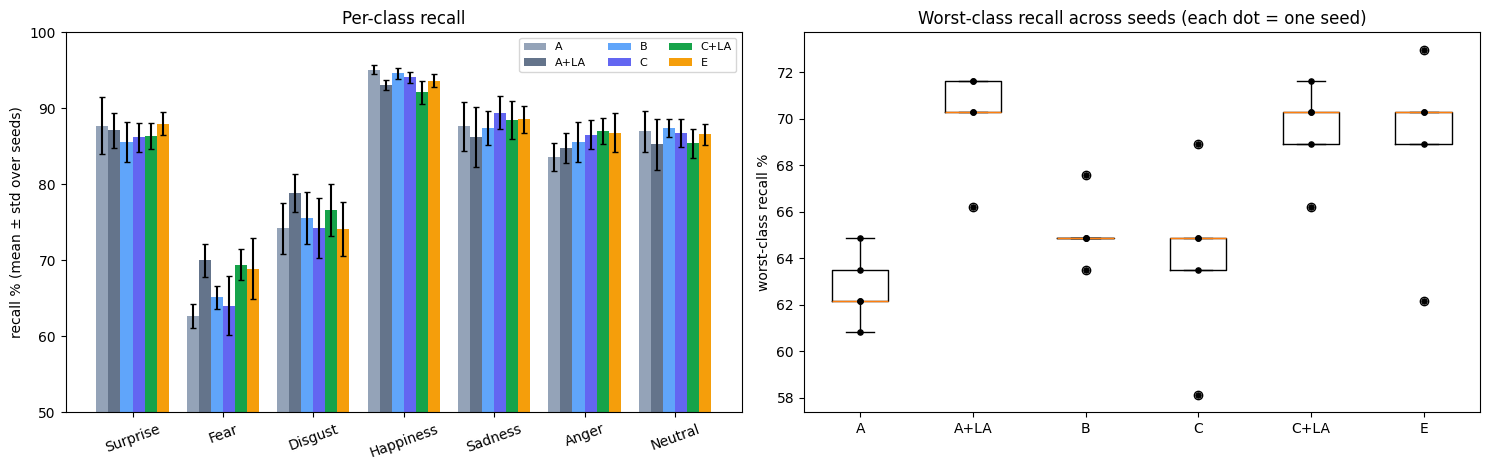

Per-class recall (mean %):


,rec_Surprise,rec_Fear,rec_Disgust,rec_Happiness,rec_Sadness,rec_Anger,rec_Neutral
system,,,,,,,
A,87.7,62.7,74.2,95.1,87.6,83.6,87.0
A+LA,87.1,70.0,78.9,93.1,86.2,84.8,85.3
B,85.6,65.1,75.6,94.6,87.4,85.6,87.4
C,86.2,64.1,74.2,94.1,89.4,86.5,86.8
C+LA,86.4,69.5,76.6,92.1,88.5,87.0,85.4
E,88.0,68.9,74.1,93.7,88.5,86.8,86.6


In [14]:
import matplotlib.pyplot as plt
colors = {"A": "#94a3b8", "A+LA": "#64748b", "B": "#60a5fa", "C": "#6366f1", "C+LA": "#16a34a", "E": "#f59e0b"}
rec_cols = [f"rec_{n}" for n in NAMES]
m = runs.groupby("system", sort=False)[rec_cols].mean() * 100
sd = runs.groupby("system", sort=False)[rec_cols].std() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
w = 0.8 / len(SYSTEMS)
for i, s in enumerate(SYSTEMS):
    ax[0].bar(np.arange(7) + i * w, m.loc[s], w, yerr=sd.loc[s], capsize=2, label=s, color=colors[s])
ax[0].set_xticks(np.arange(7) + 0.4 - w / 2); ax[0].set_xticklabels(NAMES, rotation=20)
ax[0].set_ylabel("recall % (mean ± std over seeds)"); ax[0].set_ylim(50, 100); ax[0].legend(ncol=3, fontsize=8)
ax[0].set_title("Per-class recall")
data = [runs[runs.system == s]["worst_recall"].values * 100 for s in SYSTEMS]
ax[1].boxplot(data); ax[1].set_xticks(range(1, len(SYSTEMS) + 1)); ax[1].set_xticklabels(list(SYSTEMS))

for i, d in enumerate(data, 1): ax[1].scatter([i] * len(d), d, color="k", s=14, zorder=3)
ax[1].set_ylabel("worst-class recall %"); ax[1].set_title("Worst-class recall across seeds (each dot = one seed)")
plt.tight_layout(); plt.savefig(os.path.join(STUDY_DIR, "fairness_study.png"), dpi=200); plt.show()
print("Per-class recall (mean %):"); display(m.round(1))

## 10. Paper-ready outputs

In [15]:
# Markdown + LaTeX version of the main table, plus a JSON of everything
main = table.copy()
main.columns = ["Acc", "Bal.Acc", "Macro-F1", "Worst-class recall", "Recall gap", "Recall ratio", "Minority recall"]
print(main.to_markdown()) if hasattr(main, "to_markdown") else print(main)
try:
    open(os.path.join(STUDY_DIR, "main_table.tex"), "w").write(main.to_latex())
except Exception as e:
    print("latex export skipped:", e)
runs.to_csv(os.path.join(STUDY_DIR, "per_run_results.csv"), index=False)
for s, df in comparisons.items(): df.to_csv(os.path.join(STUDY_DIR, f"compare_{s}_vs_A.csv"), index=False)
json.dump({"seeds": SEEDS, "table": main.to_dict(), "tau_used": {f"{k[0]}_{k[1]}": v for k, v in TAU_USED.items()}},
          open(os.path.join(STUDY_DIR, "fairness_study_summary.json"), "w"), indent=1)
print("saved to", STUDY_DIR)

|      | Acc          | Bal.Acc      | Macro-F1     | Worst-class recall   | Recall gap   | Recall ratio   | Minority recall   |
|:-----|:-------------|:-------------|:-------------|:---------------------|:-------------|:---------------|:------------------|
| A    | 88.87 ± 0.48 | 82.56 ± 0.40 | 82.87 ± 0.35 | 62.70 ± 1.54         | 32.40 ± 1.73 | 0.659 ± 0.017  | 73.51 ± 0.87      |
| A+LA | 87.91 ± 0.88 | 83.63 ± 0.39 | 81.45 ± 0.90 | 70.00 ± 2.22         | 23.10 ± 1.95 | 0.752 ± 0.022  | 77.90 ± 1.27      |
| B    | 88.75 ± 0.68 | 83.06 ± 0.58 | 82.82 ± 0.65 | 65.14 ± 1.48         | 29.46 ± 1.53 | 0.689 ± 0.016  | 75.44 ± 1.19      |
| C    | 88.75 ± 0.51 | 83.05 ± 0.91 | 82.90 ± 1.02 | 64.05 ± 3.89         | 30.06 ± 3.58 | 0.681 ± 0.039  | 74.95 ± 1.91      |
| C+LA | 87.82 ± 0.83 | 83.64 ± 0.52 | 81.33 ± 1.83 | 69.46 ± 2.05         | 22.78 ± 1.70 | 0.753 ± 0.019  | 77.71 ± 0.73      |
| E    | 88.70 ± 0.43 | 83.80 ± 0.68 | 82.86 ± 0.54 | 68.92 ± 4.05         | 24.74 ± 4.22 | 0.736

## 11. How to read the result (honest reporting guide)

* **Fairness helped** only if, versus A, the *worst-class recall* and *minority recall* go **up**, the *recall gap* goes **down**, **and** the bootstrap CI excludes 0 (or the paired-t p < 0.05) in section 8.
* If the CI includes 0, write "no statistically significant difference" – that is a valid, publishable finding ("simple class-balance mitigations do not reliably improve worst-class fairness on RAF-DB").
* Report **accuracy vs balanced accuracy**: a fairness method often trades a little overall accuracy for minority-class recall; the table shows that trade-off.
* Check the ablation: which component (B weights, C selection, +LA post-hoc, E stronger weights) is responsible for any gain.
* Limitations to state: single dataset (RAF-DB), emotion-class fairness only (no demographic labels in this dataset copy), fixed validation split.
* Optional extension: if you have the RAF-DB manual attribute files (gender/race/age), the earlier `fairness.py --attributes` audit can be run on any checkpoint in `fairness_study/` to add demographic fairness.